Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset.csv
Loaded file: placement_predict_50k Dataset.csv
Dataset shape: (50000, 32)
Scaling completed
Completed k = 2
Completed k = 3
Completed k = 4
Completed k = 5
Completed k = 6
Completed k = 7
Completed k = 8
Completed k = 9
Completed k = 10


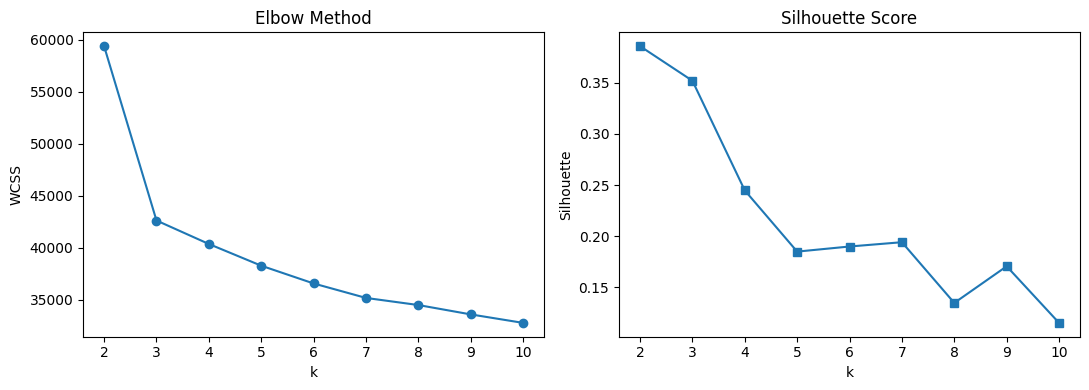


Best k = 2
K-Means completed
Hierarchical clustering completed on 5000-sample
DBSCAN eps = 1.8607223917960922
DBSCAN completed


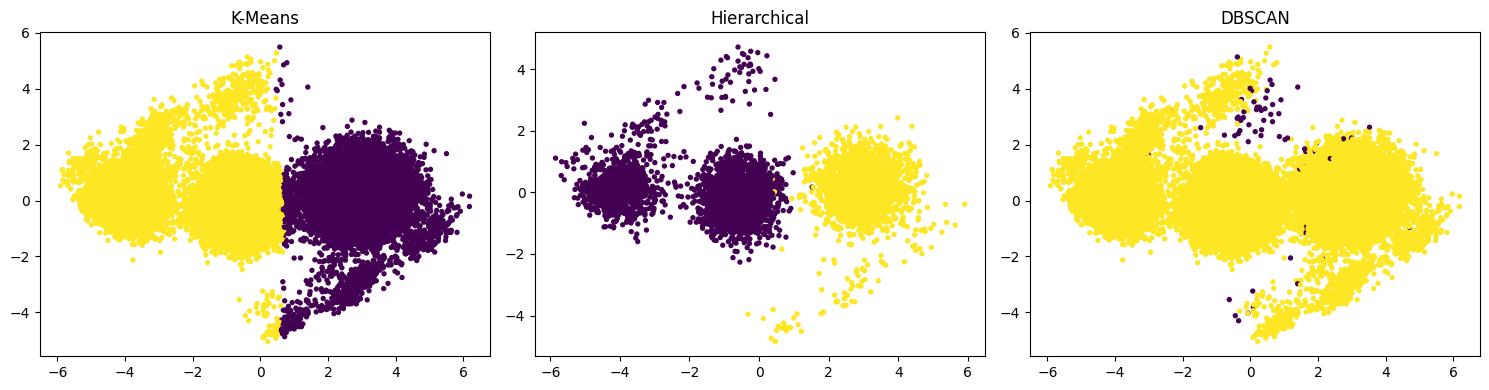

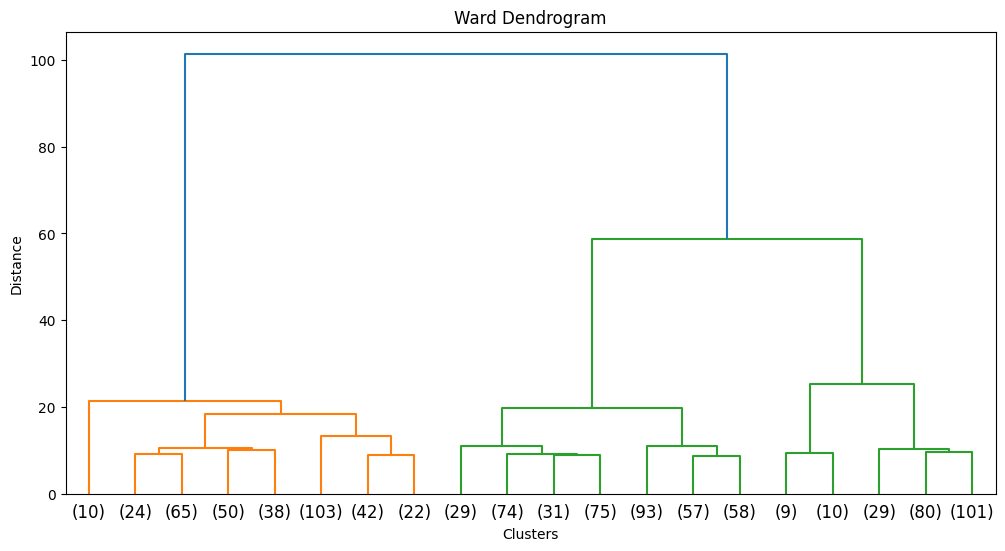


Placement Status values:
PlacementStatus
1    32856
0    17144
Name: count, dtype: int64

Converted placement values:
placed_numeric
NaN    50000
Name: count, dtype: int64

Students with valid placement labels: 0

========== RESULTS ==========
K-Means       clusters=2 silhouette=0.386 ARI=1.000
Hierarchical  clusters=2 silhouette=0.383 ARI=1.000

========== K-MEANS CLUSTER PROFILE ==========
         CGPA  AttendancePercent  Internships  Projects  Workshops  \
cluster                                                              
0        8.57              87.17         1.84      3.27       2.75   
1        6.50              70.79         0.72      1.45       1.27   

         Certifications  Publications  AptitudeTestScore  SoftSkillsRating  \
cluster                                                                      
0                  3.04          1.36              82.48              4.02   
1                  1.31          0.38              61.12              2.66   

         C

In [1]:
# Experiment 9 : Clustering

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage


# ============================================================
# 1. LOAD DATASET
# ============================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Loaded file:", filename)
print("Dataset shape:", df.shape)


# ============================================================
# 2. FEATURES
# ============================================================

F = [
    "CGPA",
    "AttendancePercent",
    "Internships",
    "Projects",
    "Workshops",
    "Certifications",
    "Publications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "CodingTestScore",
    "MockInterviewScore"
]

X_data = df[F].copy()

X_data = X_data.fillna(X_data.median())


# ============================================================
# 3. STANDARDIZATION
# ============================================================

scaler = StandardScaler()

X = scaler.fit_transform(X_data)

print("Scaling completed")


# ============================================================
# 4. PCA
# ============================================================

pca = PCA(
    n_components=2,
    random_state=0
)

X2 = pca.fit_transform(X)


# ============================================================
# 5. ELBOW + SILHOUETTE
# ============================================================

ks = range(2, 11)

wcss = []
sil = []

# Silhouette on a sample to make it faster
rng = np.random.RandomState(0)

sample_idx = rng.choice(
    len(X),
    min(10000, len(X)),
    replace=False
)

X_sil = X[sample_idx]

for k in ks:

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0
    )

    labels_sample = model.fit_predict(X_sil)

    wcss.append(
        model.inertia_
    )

    sil.append(
        silhouette_score(
            X_sil,
            labels_sample
        )
    )

    print("Completed k =", k)


# ============================================================
# 6. PLOTS
# ============================================================

fig, ax = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

ax[0].plot(
    ks,
    wcss,
    'o-'
)

ax[0].set_title("Elbow Method")
ax[0].set_xlabel("k")
ax[0].set_ylabel("WCSS")


ax[1].plot(
    ks,
    sil,
    's-'
)

ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette")


plt.tight_layout()
plt.show()


# ============================================================
# 7. BEST K
# ============================================================

k = list(ks)[int(np.argmax(sil))]

print("\nBest k =", k)


# ============================================================
# 8. K-MEANS
# ============================================================

km_model = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=0
)

km = km_model.fit_predict(X)

print("K-Means completed")


# ============================================================
# 9. HIERARCHICAL CLUSTERING
# ============================================================

# Agglomerative clustering on a sample because
# 50,000 observations is computationally expensive.

agg_idx = rng.choice(
    len(X),
    min(5000, len(X)),
    replace=False
)

X_agg = X[agg_idx]

agg = AgglomerativeClustering(
    n_clusters=k
).fit_predict(X_agg)

print("Hierarchical clustering completed on 5000-sample")


# ============================================================
# 10. DBSCAN
# ============================================================

# Use a sample to estimate eps
db_idx = rng.choice(
    len(X),
    min(10000, len(X)),
    replace=False
)

X_db = X[db_idx]

neighbors = NearestNeighbors(
    n_neighbors=16
)

neighbors.fit(X_db)

distances, _ = neighbors.kneighbors(X_db)

k_distances = np.sort(
    distances[:, -1]
)

eps = float(
    np.percentile(
        k_distances,
        92
    )
)

print("DBSCAN eps =", eps)


db = DBSCAN(
    eps=eps,
    min_samples=16
).fit_predict(X)


print("DBSCAN completed")


# ============================================================
# 11. PCA VISUALIZATION
# ============================================================

fig, ax = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)


# K-Means
ax[0].scatter(
    X2[:, 0],
    X2[:, 1],
    c=km,
    cmap="viridis",
    s=8
)

ax[0].set_title("K-Means")


# Hierarchical sample
X2_agg = X2[agg_idx]

ax[1].scatter(
    X2_agg[:, 0],
    X2_agg[:, 1],
    c=agg,
    cmap="viridis",
    s=8
)

ax[1].set_title("Hierarchical")


# DBSCAN
ax[2].scatter(
    X2[:, 0],
    X2[:, 1],
    c=db,
    cmap="viridis",
    s=8
)

ax[2].set_title("DBSCAN")


plt.tight_layout()
plt.show()


# ============================================================
# 12. WARD DENDROGRAM
# ============================================================

# NEVER create a dendrogram using all 50,000 records.

dendro_idx = rng.choice(
    len(X),
    min(1000, len(X)),
    replace=False
)

X_dendro = X[dendro_idx]

plt.figure(figsize=(12, 6))

dendrogram(
    linkage(
        X_dendro,
        method="ward"
    ),
    truncate_mode="lastp",
    p=20
)

plt.title("Ward Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")

plt.show()





   # ============================================================
# 13. PLACEMENT STATUS
# ============================================================

print("\nPlacement Status values:")
print(df["PlacementStatus"].value_counts(dropna=False))


# Convert PlacementStatus safely to 0 and 1
df["placed_numeric"] = (
    df["PlacementStatus"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "placed": 1,
        "not placed": 0,
        "not_placed": 0,
        "notplaced": 0
    })
)

print("\nConverted placement values:")
print(df["placed_numeric"].value_counts(dropna=False))


# ============================================================
# 14. REMOVE UNKNOWN PLACEMENT VALUES FOR ARI
# ============================================================

valid_placement = df["placed_numeric"].notna()

print(
    "\nStudents with valid placement labels:",
    valid_placement.sum()
)


# ============================================================
# 15. EVALUATION
# ============================================================

print("\n========== RESULTS ==========")


# -----------------------------
# K-MEANS
# -----------------------------

km_mask = valid_placement.iloc[sample_idx].values

km_labels = km[sample_idx][km_mask]

km_true = (
    df.loc[
        df.index[sample_idx][km_mask],
        "placed_numeric"
    ]
    .astype(int)
    .values
)

km_sil = silhouette_score(
    X_sil,
    km[sample_idx]
)

km_ari = adjusted_rand_score(
    km_true,
    km_labels
)

print(
    f"K-Means       "
    f"clusters={k} "
    f"silhouette={km_sil:.3f} "
    f"ARI={km_ari:.3f}"
)


# -----------------------------
# HIERARCHICAL
# -----------------------------

agg_mask = valid_placement.iloc[agg_idx].values

agg_labels = agg[agg_mask]

agg_true = (
    df.loc[
        df.index[agg_idx][agg_mask],
        "placed_numeric"
    ]
    .astype(int)
    .values
)

agg_sil = silhouette_score(
    X_agg,
    agg
)

agg_ari = adjusted_rand_score(
    agg_true,
    agg_labels
)

print(
    f"Hierarchical  "
    f"clusters={k} "
    f"silhouette={agg_sil:.3f} "
    f"ARI={agg_ari:.3f}"
)


# -----------------------------
# DBSCAN
# -----------------------------

db_mask = (
    (db != -1) &
    valid_placement.values
)

if len(set(db[db_mask])) > 1:

    db_sil = silhouette_score(
        X[db_mask],
        db[db_mask]
    )

    db_ari = adjusted_rand_score(
        df.loc[
            db_mask,
            "placed_numeric"
        ].astype(int),
        db[db_mask]
    )

    print(
        f"DBSCAN        "
        f"clusters={len(set(db[db_mask]))} "
        f"silhouette={db_sil:.3f} "
        f"ARI={db_ari:.3f}"
    )


# ============================================================
# 15. K-MEANS CLUSTER PROFILE
# ============================================================

df["cluster"] = km

print("\n========== K-MEANS CLUSTER PROFILE ==========")

print(
    df.groupby("cluster")[F].mean().round(2)
)


# ============================================================
# 16. PLACEMENT RATE BY CLUSTER
# ============================================================

print("\n========== PLACEMENT RATE BY CLUSTER ==========")

print(
    df.groupby("cluster")["placed_numeric"]
    .mean()
    .round(3)
)